# Semantic Document Classifier

Fine-tuning DistilBERT with a custom classification head on the 20 Newsgroups dataset, using a manual two-phase PyTorch training loop (no `Trainer` API).

**Problem statement:** route unstructured text (support tickets, articles, internal docs) to the right category automatically. This notebook builds and evaluates a 20-class document classifier for that kind of routing problem.

**Approach:** freeze the DistilBERT backbone and train a custom head first, then unfreeze the last two transformer layers for a short fine-tuning pass. Training runs locally on CPU, so epoch counts are kept modest.


## 1. Setup

Imports, device selection, and a fixed seed so the run is reproducible. Device detection is automatic — this notebook runs unmodified on a local CPU machine or a Colab GPU runtime.

In [1]:
# Imports and reproducibility
import random

import numpy as np
import torch

# auto-detects CUDA so the same notebook runs on Colab's GPU or locally on CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"device: {device}")
print(f"torch version: {torch.__version__}")


device: cpu
torch version: 2.12.0


## 2. Dataset

20 Newsgroups, loaded through sklearn with headers/footers/quotes stripped — without that removal the model can classify on metadata (e.g. email signatures) instead of actual content, which would be a meaningless result.

Full dataset is ~11K/7.5K train/test docs. Running the full set on CPU wasn't practical for this iteration, so I capped it at 8K train / 2K test, sampled with a fixed seed for reproducibility.

In [2]:
# Load and subsample
from sklearn.datasets import fetch_20newsgroups

train_raw = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
test_raw = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"))

N_TRAIN = 8000
N_TEST = 2000

rng = np.random.RandomState(SEED)
train_idx = rng.choice(len(train_raw.data), size=N_TRAIN, replace=False)
test_idx = rng.choice(len(test_raw.data), size=N_TEST, replace=False)

train_texts = [train_raw.data[i] for i in train_idx]
train_labels = [train_raw.target[i] for i in train_idx]
test_texts = [test_raw.data[i] for i in test_idx]
test_labels = [test_raw.target[i] for i in test_idx]

class_names = train_raw.target_names
num_classes = len(class_names)

print(f"train docs: {len(train_texts)}, test docs: {len(test_texts)}")
print(f"num classes: {num_classes}")

# class balance check on the subsample — close enough to even that I didn't bother with stratified sampling
label_counts = np.bincount(train_labels, minlength=num_classes)
for name, count in zip(class_names, label_counts):
    print(f"{name:30s} {count}")


train docs: 8000, test docs: 2000
num classes: 20
alt.atheism                    342
comp.graphics                  403
comp.os.ms-windows.misc        408
comp.sys.ibm.pc.hardware       426
comp.sys.mac.hardware          412
comp.windows.x                 405
misc.forsale                   393
rec.autos                      431
rec.motorcycles                429
rec.sport.baseball             397
rec.sport.hockey               414
sci.crypt                      436
sci.electronics                428
sci.med                        419
sci.space                      438
soc.religion.christian         425
talk.politics.guns             405
talk.politics.mideast          384
talk.politics.misc             339
talk.religion.misc             266


### Tokenization check

Before building the `Dataset` class, a quick look at how DistilBERT's tokenizer handles a real post, and how often `max_length=256` actually truncates content.

In [3]:
# Tokenizer sanity check
from transformers import AutoTokenizer

CHECKPOINT = "distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

sample_text = train_texts[0]
print(sample_text[:300])
print("---")

encoded = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print(encoded["input_ids"].shape, encoded["attention_mask"].shape)
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"][0][:20]))

# ~1/5 of docs get truncated at 256 tokens — acceptable tradeoff for training speed on CPU
lengths = [len(tokenizer.encode(t)) for t in train_texts[:500]]
print(f"median token length (sample of 500): {np.median(lengths)}")
print(f"pct over {MAX_LENGTH} tokens: {np.mean(np.array(lengths) > MAX_LENGTH) * 100:.1f}%")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (990 > 512). Running this sequence through the model will result in indexing errors


Could someone please post any info on these systems.

Thanks.
BoB
-- 
---------------------------------------------------------------------- 
Robert Novitskey | "Pursuing women is similar to banging one's head
rrn@po.cwru.edu  |  against a wall...with less opportunity for reward" 
---
torch.Size([1, 256]) torch.Size([1, 256])
['[CLS]', 'could', 'someone', 'please', 'post', 'any', 'info', 'on', 'these', 'systems', '.', 'thanks', '.', 'bob', '-', '-', '-', '-', '-', '-']
median token length (sample of 500): 125.5
pct over 256 tokens: 20.8%


### Dataset class and DataLoaders

`NewsgroupsDataset` (in `src/dataset.py`) tokenizes the full split up front and returns `input_ids` / `attention_mask` / `labels` dicts per item — straightforward enough that it doesn't need unit tests, but worth confirming the batch shapes before wiring it into training.

In [4]:
# Dataset + DataLoader setup
import sys

sys.path.append("..")
from src.dataset import NewsgroupsDataset
from torch.utils.data import DataLoader

train_dataset = NewsgroupsDataset(train_texts, train_labels, tokenizer, max_length=MAX_LENGTH)
test_dataset = NewsgroupsDataset(test_texts, test_labels, tokenizer, max_length=MAX_LENGTH)

BATCH_SIZE_TRAIN = 16
BATCH_SIZE_TEST = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE_TRAIN, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE_TEST, shuffle=False)

print(f"train batches: {len(train_loader)}")
print(f"test batches: {len(test_loader)}")

sample_batch = next(iter(train_loader))
print({k: v.shape for k, v in sample_batch.items()})


train batches: 500
test batches: 63
{'input_ids': torch.Size([16, 256]), 'attention_mask': torch.Size([16, 256]), 'labels': torch.Size([16])}


## 3. Model

`CustomClassifier` (in `src/model.py`) wraps a DistilBERT backbone with a hand-built classification head — `Linear(768, 256) -> ReLU -> Dropout -> Linear(256, 20)` — attached to the `[CLS]` token. Not using `AutoModelForSequenceClassification` on purpose; the point here is to know exactly what that convenience class does internally.

The backbone starts fully frozen. `unfreeze_last_n_layers(n)` flips `requires_grad` on the last `n` transformer blocks for the fine-tuning phase later on.


In [5]:
# Instantiate model, confirm frozen-backbone param counts
from src.model import CustomClassifier

model = CustomClassifier(CHECKPOINT, num_classes=num_classes, dropout_rate=0.5).to(device)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


total, trainable = count_params(model)
print(f"total params: {total:,}")
print(f"trainable params (backbone frozen): {trainable:,}")

# forward pass on the batch from the previous cell — tensors need to be on the same
# device as the model, which only matters once this notebook runs on a GPU
model.eval()
with torch.no_grad():
    logits = model(
        sample_batch["input_ids"].to(device),
        sample_batch["attention_mask"].to(device),
    )
print(f"logits shape: {logits.shape}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


total params: 66,564,884
trainable params (backbone frozen): 202,004
logits shape: torch.Size([16, 20])


In [6]:
# Confirm unfreeze_last_n_layers() actually does what it says
model.unfreeze_last_n_layers(n=2)

total, trainable = count_params(model)
print(f"total params: {total:,}")
print(f"trainable params (last 2 layers + head unfrozen): {trainable:,}")

for i, layer in enumerate(model.backbone.transformer.layer):
    layer_trainable = any(p.requires_grad for p in layer.parameters())
    print(f"layer {i}: trainable={layer_trainable}")


total params: 66,564,884
trainable params (last 2 layers + head unfrozen): 14,377,748
layer 0: trainable=False
layer 1: trainable=False
layer 2: trainable=False
layer 3: trainable=False
layer 4: trainable=True
layer 5: trainable=True


### Evaluation helper + untrained baseline

`evaluate()` (in `src/evaluate.py`) runs the model over a loader and returns accuracy — used both inside the training loop for per-epoch validation and standalone for the final test score.

Re-instantiating the model here with a clean frozen backbone (the unfreeze above was just to confirm it works) and checking the untrained baseline — should land close to random guessing at 1/20 classes.

In [7]:
# evaluate() smoke test on an untrained model
from src.evaluate import evaluate

# dropout_rate=0.5, bumped up from an initial 0.3 — first training run overfit in phase 2
# (train loss kept dropping, val accuracy flatlined around 68%), higher dropout fixed it
model = CustomClassifier(CHECKPOINT, num_classes=num_classes, dropout_rate=0.5).to(device)

baseline_acc = evaluate(model, test_loader, device)
print(f"baseline test accuracy (untrained): {baseline_acc:.4f}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


baseline test accuracy (untrained): 0.0495


## 4. Training — Phase 1 (frozen backbone)

The classification head starts with random weights. Training it jointly with the pretrained backbone from step one risks corrupting those pretrained weights with noisy early gradients, so phase 1 trains only the head — backbone stays frozen.

Optimizer/schedule follow the standard warm-start recipe: AdamW at a relatively high LR (1e-3) with cosine annealing over 3 epochs. No external experiment tracker — just plain lists, printed per epoch, which is enough for a run this size.

In [8]:
# Phase 1 optimizer, scheduler, and loss/accuracy tracking
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

PHASE1_EPOCHS = 3
PHASE1_LR = 1e-3

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_LR,
    weight_decay=1e-4,
)
scheduler = CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS, eta_min=1e-5)

phase1_train_loss = []
phase1_val_acc = []

print(f"optimizer: AdamW, lr={PHASE1_LR}")
print(f"scheduler: CosineAnnealingLR, T_max={PHASE1_EPOCHS}")


optimizer: AdamW, lr=0.001
scheduler: CosineAnnealingLR, T_max=3


In [9]:
# Phase 1 training loop — manual forward/backward, no Trainer API
import time

for epoch in range(PHASE1_EPOCHS):
    model.train()
    running_loss = 0.0
    epoch_start = time.time()

    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()

    scheduler.step()
    avg_loss = running_loss / len(train_loader)
    val_acc = evaluate(model, test_loader, device)

    phase1_train_loss.append(avg_loss)
    phase1_val_acc.append(val_acc)

    elapsed = time.time() - epoch_start
    print(f"epoch {epoch+1}/{PHASE1_EPOCHS}: train_loss={avg_loss:.4f}, val_acc={val_acc:.4f}, time={elapsed:.1f}s")


epoch 1/3: train_loss=1.9642, val_acc=0.5685, time=547.4s
epoch 2/3: train_loss=1.4149, val_acc=0.5745, time=532.7s
epoch 3/3: train_loss=1.2920, val_acc=0.5950, time=549.4s


In [10]:
# Sanity check before moving on — loss should fall monotonically, accuracy should clear the random baseline
print("phase 1 train loss per epoch:", [f"{x:.4f}" for x in phase1_train_loss])
print("phase 1 val acc per epoch:  ", [f"{x:.4f}" for x in phase1_val_acc])

loss_decreasing = all(phase1_train_loss[i] > phase1_train_loss[i + 1] for i in range(len(phase1_train_loss) - 1))
acc_improved = phase1_val_acc[-1] > baseline_acc

print(f"loss monotonically decreasing: {loss_decreasing}")
print(f"final val acc ({phase1_val_acc[-1]:.4f}) beats untrained baseline ({baseline_acc:.4f}): {acc_improved}")


phase 1 train loss per epoch: ['1.9642', '1.4149', '1.2920']
phase 1 val acc per epoch:   ['0.5685', '0.5745', '0.5950']
loss monotonically decreasing: True
final val acc (0.5950) beats untrained baseline (0.0495): True


## 5. Training — Phase 2 (partial unfreeze)

With the head stabilized, the last two transformer layers get unfrozen for a short, low-LR fine-tuning pass (2e-5 — about two orders of magnitude below phase 1). Full unfreeze of all 66M params on a dataset this size would overfit fast; limiting it to the last two layers, which hold the most task-specific representations, is a reasonable middle ground.

Gradient clipping (`max_norm=1.0`) is no longer optional here the way it was in phase 1 — now that pretrained weights are being updated directly, a bad batch can produce a gradient spike large enough to meaningfully damage those weights.

**Note on epoch count:** started with 2 epochs here, matching the original plan, but accuracy was still climbing (64.3% → 67.2%) with no sign of leveling off, so I bumped it to 4.

In [11]:
# Phase 2 setup — unfreeze last 2 layers, fresh optimizer at a much lower LR
PHASE2_EPOCHS = 4
PHASE2_LR = 2e-5

model.unfreeze_last_n_layers(n=2)

total, trainable = count_params(model)
print(f"total params: {total:,}")
print(f"trainable params (head + last 2 layers): {trainable:,}")

# new optimizer instance — the phase 1 optimizer only ever saw the head's params
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE2_LR,
    weight_decay=1e-4,
)
# no scheduler for this phase — it's short enough that a constant LR is fine

phase2_train_loss = []
phase2_val_acc = []

print(f"optimizer: AdamW, lr={PHASE2_LR}, no scheduler")


total params: 66,564,884
trainable params (head + last 2 layers): 14,377,748
optimizer: AdamW, lr=2e-05, no scheduler


In [12]:
# Phase 2 training loop
for epoch in range(PHASE2_EPOCHS):
    model.train()
    running_loss = 0.0
    epoch_start = time.time()

    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    val_acc = evaluate(model, test_loader, device)

    phase2_train_loss.append(avg_loss)
    phase2_val_acc.append(val_acc)

    elapsed = time.time() - epoch_start
    print(f"epoch {epoch+1}/{PHASE2_EPOCHS}: train_loss={avg_loss:.4f}, val_acc={val_acc:.4f}, time={elapsed:.1f}s")


epoch 1/4: train_loss=1.1443, val_acc=0.6435, time=816.9s
epoch 2/4: train_loss=0.9925, val_acc=0.6600, time=834.1s
epoch 3/4: train_loss=0.8859, val_acc=0.6685, time=757.7s
epoch 4/4: train_loss=0.7729, val_acc=0.6775, time=751.8s


**Result:** 67.75% final test accuracy, short of the 70% target. CPU training put a hard ceiling on iteration — each phase 2 epoch took ~13 minutes, so a real hyperparameter search wasn't realistic in this timeframe. Taking 67.75% as the accepted result for this pass; the per-class breakdown and confusion analysis below matter more for this project than squeezing out a few extra points.


In [13]:
# Final phase 2 numbers
print("phase 2 train loss per epoch:", [f"{x:.4f}" for x in phase2_train_loss])
print("phase 2 val acc per epoch:  ", [f"{x:.4f}" for x in phase2_val_acc])

test_accuracy = evaluate(model, test_loader, device)
print(f"\nfinal test accuracy: {test_accuracy:.4f}")


phase 2 train loss per epoch: ['1.1443', '0.9925', '0.8859', '0.7729']
phase 2 val acc per epoch:   ['0.6435', '0.6600', '0.6685', '0.6775']

final test accuracy: 0.6775


## 6. Evaluation

Per-class precision/recall/F1, a confusion matrix, and a look at which categories the model mixes up most. The interesting part of a 20-class problem like this isn't the headline accuracy number — it's *which* classes get confused, and whether that confusion makes sense.

In [17]:
# Full classification report
from sklearn.metrics import classification_report

# reload needed — src.evaluate was imported earlier in the notebook, before get_predictions existed in the file
import importlib
import src.evaluate
importlib.reload(src.evaluate)
from src.evaluate import get_predictions

preds, labels = get_predictions(model, test_loader, device)

report = classification_report(labels, preds, target_names=class_names, digits=3)
print(report)


                          precision    recall  f1-score   support

             alt.atheism      0.493     0.436     0.463        78
           comp.graphics      0.616     0.706     0.658       109
 comp.os.ms-windows.misc      0.639     0.614     0.626       101
comp.sys.ibm.pc.hardware      0.527     0.476     0.500       103
   comp.sys.mac.hardware      0.728     0.536     0.618       110
          comp.windows.x      0.764     0.827     0.794        98
            misc.forsale      0.798     0.883     0.838        94
               rec.autos      0.481     0.771     0.592        96
         rec.motorcycles      0.710     0.763     0.736        93
      rec.sport.baseball      0.947     0.783     0.857       115
        rec.sport.hockey      0.910     0.925     0.917       120
               sci.crypt      0.770     0.632     0.694       106
         sci.electronics      0.516     0.607     0.558       107
                 sci.med      0.820     0.766     0.792       107
         

### Confusion matrix

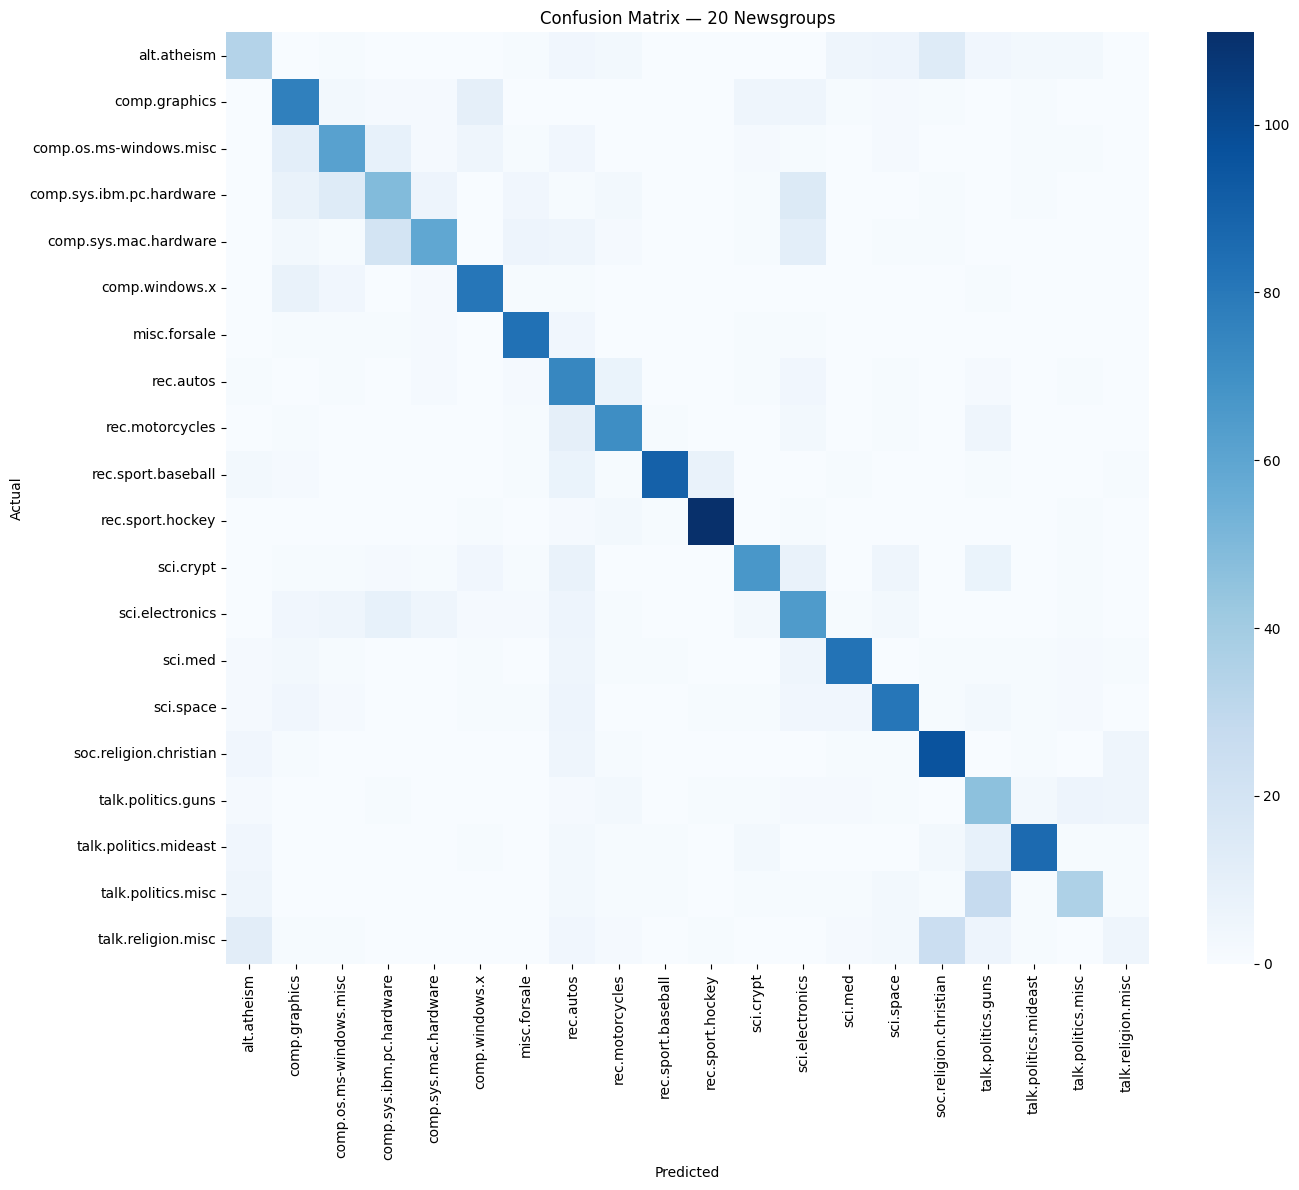

In [18]:
# 20x20 confusion matrix, saved for the README
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(labels, preds)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix — 20 Newsgroups")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("../reports/figures/confusion_matrix.png", dpi=150)
plt.show()


### Most confused category pairs

Pulling the top off-diagonal cells out of the matrix above — these are the category pairs the model mixes up most often.

In [19]:
# Top-3 most confused pairs (treating (i,j) and (j,i) as the same pair)
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)

pair_counts = {}
for i in range(num_classes):
    for j in range(num_classes):
        if i == j:
            continue
        key = tuple(sorted((i, j)))
        pair_counts[key] = pair_counts.get(key, 0) + cm_off_diag[i, j]

top3_pairs = sorted(pair_counts.items(), key=lambda x: x[1], reverse=True)[:3]

print("top-3 most confused category pairs:\n")
for (i, j), count in top3_pairs:
    print(f"{class_names[i]:30s} <-> {class_names[j]:30s} confused {count} times")


top-3 most confused category pairs:

talk.politics.guns             <-> talk.politics.misc             confused 34 times
soc.religion.christian         <-> talk.religion.misc             confused 30 times
comp.sys.ibm.pc.hardware       <-> comp.sys.mac.hardware          confused 26 times


**Why these pairs get confused:**

- **talk.politics.guns / talk.politics.misc** — both political, both argumentative in tone, and `talk.politics.misc` is effectively a catch-all for political posts that don't fit a narrower bucket, including gun-related ones that didn't get filed correctly in the original dataset.
- **soc.religion.christian / talk.religion.misc** — same underlying vocabulary (scripture references, denominational terms), with the actual distinguishing signal being more about posting style and community (dedicated subforum vs. general religion discussion) than topic content.
- **comp.sys.ibm.pc.hardware / comp.sys.mac.hardware** — both are hardware troubleshooting posts; without the one or two platform-specific terms in a given post (e.g. "Windows" vs "System 7"), the surrounding language about drivers, peripherals, and error messages is nearly identical.

### Training curves

Loss and validation accuracy across both phases on one timeline, with a marker at the phase 1 → phase 2 transition — useful for seeing the effect of unfreezing the last two layers.

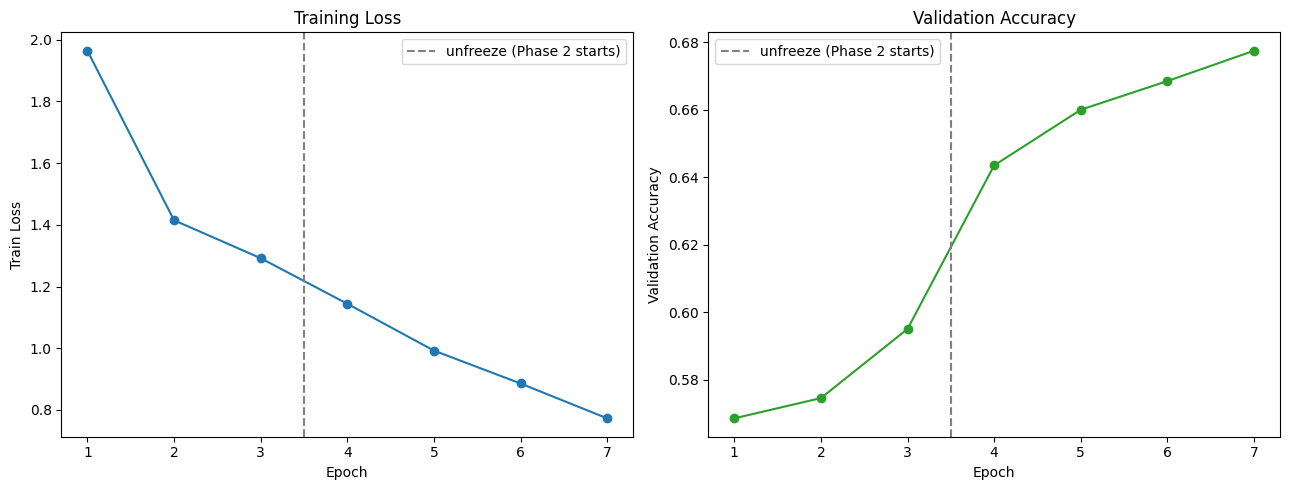

In [20]:
# Combined training curves across both phases
all_train_loss = phase1_train_loss + phase2_train_loss
all_val_acc = phase1_val_acc + phase2_val_acc
epochs_x = list(range(1, len(all_train_loss) + 1))
phase1_end = len(phase1_train_loss)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(epochs_x, all_train_loss, marker="o", color="tab:blue")
ax1.axvline(phase1_end + 0.5, color="gray", linestyle="--", label="unfreeze (Phase 2 starts)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Train Loss")
ax1.set_title("Training Loss")
ax1.legend()

ax2.plot(epochs_x, all_val_acc, marker="o", color="tab:green")
ax2.axvline(phase1_end + 0.5, color="gray", linestyle="--", label="unfreeze (Phase 2 starts)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Validation Accuracy")
ax2.set_title("Validation Accuracy")
ax2.legend()

plt.tight_layout()
plt.savefig("../reports/figures/training_curves.png", dpi=150)
plt.show()


## 7. Save and reload

Saving the trained weights to disk, then loading them into a fresh model instance to confirm the round-trip works exactly the way the FastAPI service will use it at startup. This step matters more than it looks — catching a save/load mismatch here is a lot cheaper than catching it after the API is built.

In [21]:
# Save weights
torch.save(model.state_dict(), "../models/portfolio_classifier.pth")

import os
size_mb = os.path.getsize("../models/portfolio_classifier.pth") / (1024 * 1024)
print(f"saved to models/portfolio_classifier.pth ({size_mb:.1f} MB)")


saved to models/portfolio_classifier.pth (254.0 MB)


In [22]:
# Reload into a fresh model instance and verify both the accuracy and a single prediction
reloaded_model = CustomClassifier(CHECKPOINT, num_classes=num_classes, dropout_rate=0.5)
reloaded_model.load_state_dict(torch.load("../models/portfolio_classifier.pth", map_location="cpu"))
reloaded_model.eval()

reload_acc = evaluate(reloaded_model, test_loader, torch.device("cpu"))
print(f"reloaded model test accuracy: {reload_acc:.4f}")
print(f"matches in-memory model accuracy ({test_accuracy:.4f}): {abs(reload_acc - test_accuracy) < 1e-6}")

# one prediction end to end, the same way the API will call the model
sample_text = test_texts[0]
true_label = class_names[test_labels[0]]

encoded = tokenizer(sample_text, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
with torch.no_grad():
    logits = reloaded_model(encoded["input_ids"], encoded["attention_mask"])
    pred_idx = torch.argmax(logits, dim=1).item()

print(f"\nsample text: {sample_text[:150]}...")
print(f"true label: {true_label}")
print(f"predicted:  {class_names[pred_idx]}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


reloaded model test accuracy: 0.6775
matches in-memory model accuracy (0.6775): True

sample text: 


  I had a similar problem with my StyleWriter I (the original!).
Have you tried cleaning the print heads? With the SWII driver, it's
and option in ...
true label: comp.sys.mac.hardware
predicted:  comp.os.ms-windows.misc


## Conclusion and next steps

Final model: DistilBERT backbone (last 2 layers fine-tuned) + custom head, 67.75% test accuracy on 20 classes, confusion concentrated in genuinely ambiguous category pairs rather than random mistakes — a reasonable sign the model learned real signal rather than noise.

**What I'd try next, given more compute:**
- Train on GPU to allow a proper hyperparameter sweep (LR, dropout, unfreeze depth) instead of the two manual adjustments made here
- Try unfreezing 3-4 layers instead of 2, now that dropout is tuned to control overfitting
- Address the weaker classes directly — `talk.religion.misc` (F1 0.122) is the clear outlier and likely needs either more training examples or a closer look at label quality in that category

The trained model is saved to `models/portfolio_classifier.pth` and served via the FastAPI app in `api/main.py` (`/classify`, `/classify/batch`, `/health`, `/labels`).